# LaStBeRu × Rubin reference catalog

This notebook runs the large-catalog workflow in separate stages:

1. **TAP coverage:** counts individual images and summarizes seeing, limiting magnitude, exposure time, and epochs by band.
2. **Coadd properties:** optionally samples coadd quality maps only for targets with individual-image coverage.
3. **Cutouts:** optionally loads full coadds only for the prioritized targets.

Run the first stage over all targets before enabling the more expensive stages.

**Criterio geométrico actual:** `detector_search_radius_deg=0.35` es solo un radio de preselección para traer detectores candidatos. El matching final considera que el punto RA/DEC del target esté dentro del cuadrilátero del detector; no considera todavía un disco de 10 arcsec alrededor del target.


In [1]:
from pathlib import Path
from dataclasses import replace
import json
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from target_selection import (
    load_reference_catalog_config,
    run_reference_coverage_catalog,
    enrich_reference_catalog_coadds,
    generate_reference_catalog_cutouts,
)

_repo_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next(
    (parent for parent in _repo_candidates if (parent / "configs" / "lastberu_dp2.toml").exists()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook from the target_selection repository or its notebooks/ directory.")

CONFIG_PATH = REPO_ROOT / "configs" / "lastberu_dp2.toml"
TARGET_LIMIT = None  # Set None for all targets.
RUN_COVERAGE = False  # reutiliza coverage_catalog.csv si ya existe
RUN_COADD_DETECTION = True
RUN_COADD_PROPERTIES = True
RUN_CUTOUTS = True  # Generate the configured A/B cutouts
REGENERATE_CUTOUTS = False  # Set False after the new layout has been generated.
MAX_CUTOUTS = 100_000  # procesa todos los candidatos A/B

config = load_reference_catalog_config(CONFIG_PATH)
run_name = config.name if TARGET_LIMIT is None else f"{config.name}_preview_{TARGET_LIMIT}"
config = replace(
    config,
    name=run_name,
    target_limit=TARGET_LIMIT,
    max_cutouts=MAX_CUTOUTS,
    save_cutout_fits=True,
    input_path=str(REPO_ROOT / config.input_path),
    output_dir=str(REPO_ROOT / config.output_dir),
    cache_dir=str(REPO_ROOT / config.cache_dir),
)
output_directory = Path(config.output_dir) / config.name
FITS_OUTPUT_DIR = REPO_ROOT / "delete_sundays"
config

ReferenceCatalogConfig(input_path='/home/karennowo/target_selection/data/LaStBeRu_data/LaStBeRu_watchlist_LSST_grades.csv', name='lastberu_dp2', output_dir='/home/karennowo/target_selection/outputs/catalog_enrichment', cache_dir='/home/karennowo/target_selection/outputs/_cache/reference_catalog', data_release='DP2', target_id_column='object_id', ra_column='ra', dec_column='dec', extra_info_column='extra_info', bands=('u', 'g', 'r', 'i', 'z', 'y'), property_maps=('maglim', 'psf_size', 'exposure_time', 'sky_noise'), coadd_skymap='lsst_cells_v2', coadd_pixel_scale_arcsec=0.2, partial_property_map_reads=True, visit_query_scope='coadd', tap_tile_nside=64, tap_max_workers=2, tap_timeout_seconds=7200, detector_search_radius_deg=0.35, target_limit=None, reuse_cache=True, generate_cutouts=True, max_cutouts=100000, cutout_size_arcsec=20.0, cutout_grades=('A', 'B'), cutout_bands=('u', 'g', 'r', 'i', 'z', 'y'), save_cutout_fits=True, verbose=True)

## 1. TAP coverage and individual-image summaries

This is the fast first pass. It does not initialize Butler and does not read coadd maps.

**Criterio geométrico actual:** `detector_search_radius_deg=0.35` es solo un radio de preselección para traer detectores candidatos. El matching final considera que el punto RA/DEC del target esté dentro del cuadrilátero del detector; no considera todavía un disco de 10 arcsec alrededor del target.


In [2]:
coverage_path = output_directory / "coverage_catalog.csv"
if RUN_COVERAGE:
    coverage_catalog = run_reference_coverage_catalog(config)
elif coverage_path.exists():
    coverage_catalog = pd.read_csv(coverage_path)
else:
    raise FileNotFoundError(f"No coverage catalog at {coverage_path}. Set RUN_COVERAGE=True first.")

print(f"Coverage catalog: {len(coverage_catalog):,} targets")
coverage_catalog.head()

Coverage catalog: 35,400 targets


,object_id,ra,dec,type_label,original_source,redshift,redshift_error,redshift_label,extra_info,target_id,...,visit_last_mjd_i,visit_last_mjd_r,visit_last_mjd_u,visit_last_mjd_y,visit_last_mjd_z,n_images_total,visit_bands,visit_query_status,visit_query_error,visit_coverage_queried
0,LaStBeRu_J000001.1-350334.9,0.00471,-35.05971,Candidate SL system,Gioia et al. (1990) - doi:10.1086/191426,0.508000,-1.00000,NaN,"vetting_grade=nan,vetting_grade_survey=nan,Ori...",LaStBeRu_J000001.1-350334.9,...,61002.074832,NaN,NaN,NaN,NaN,10,"g,i",cache,NaN,True
1,LaStBeRu_J000001.2+051908.6,0.00504,5.31906,Candidate SL system,Lopes et al. (2004) - doi:10.1086/423038,0.850000,0.33321,photometric,"vetting_grade=E,vetting_grade_survey=Legacy,Or...",LaStBeRu_J000001.2+051908.6,...,60877.307573,60879.339351,NaN,NaN,60867.318089,18,"g,r,i,z",cache,NaN,True
2,LaStBeRu_J000002.2+085518.4,0.00925,8.92179,Candidate SL system,Lopes et al. (2004) - doi:10.1086/423038,-1.000000,-1.00000,NaN,"vetting_grade=E,vetting_grade_survey=Legacy,Or...",LaStBeRu_J000002.2+085518.4,...,60868.319324,60876.282115,NaN,NaN,60866.313003,18,"g,r,i,z",cache,NaN,True
3,LaStBeRu_J000006.0+081629.7,0.02512,8.27492,Candidate SL system,Lopes et al. (2004) - doi:10.1086/423038,-1.000000,-1.00000,NaN,"vetting_grade=E,vetting_grade_survey=Legacy,Or...",LaStBeRu_J000006.0+081629.7,...,60877.307573,60877.283376,NaN,NaN,60869.319762,17,"g,r,i,z",cache,NaN,True
4,LaStBeRu_J000006.1+213829.4,0.02542,21.64150,Candidate SL system,Huang et al. (2021) - arXiv:2005.04730,0.502973,-1.00000,spectroscopic,"vetting_grade=D,vetting_grade_survey=Legacy,Or...",LaStBeRu_J000006.1+213829.4,...,NaN,NaN,NaN,NaN,NaN,0,NaN,cache,NaN,True


## Exportación de visitas individuales

La consulta de cobertura se ejecuta una sola vez. `coverage_catalog` contiene una fila por target con los conteos y estadísticas agregadas por banda; los siguientes productos se generan reutilizando ese resultado, sin volver a consultar TAP.

In [3]:
# Comprobación rápida del catálogo de cobertura ya calculado.
coverage_catalog = coverage_catalog.copy()
coverage_catalog["selection_grade"] = coverage_catalog["selection_grade"].fillna("Unknown").astype(str)
coverage_catalog["n_images_total"] = pd.to_numeric(coverage_catalog["n_images_total"], errors="coerce").fillna(0).astype(int)
coverage_catalog["n_filters_with_images"] = coverage_catalog[[f"n_images_{b}" for b in config.bands]].gt(0).sum(axis=1).astype(int)
print(f"Targets en el catálogo: {len(coverage_catalog):,}")
print(f"Targets con al menos una visita: {(coverage_catalog.n_images_total > 0).sum():,}")
print(coverage_catalog["selection_grade"].value_counts(dropna=False).sort_index())


Targets en el catálogo: 35,400
Targets con al menos una visita: 14,305
selection_grade
A            126
B           1786
C           4692
D          14824
E           8216
Unknown     5756
Name: count, dtype: int64


## Detección de coadds

Esta etapa consulta Butler para saber si existe un coadd en la posición de cada target. Si `RUN_COADD_PROPERTIES=True`, también muestrea los mapas de profundidad y PSF; esos valores se usan en los resúmenes y distribuciones.

In [4]:
reference_catalog_path = output_directory / "reference_catalog.csv"
if RUN_COADD_DETECTION:
    catalog = enrich_reference_catalog_coadds(config, coverage_catalog, sample_properties=RUN_COADD_PROPERTIES)
elif reference_catalog_path.exists():
    catalog = pd.read_csv(reference_catalog_path)
else:
    raise FileNotFoundError(f"No existe {reference_catalog_path}; ejecutá RUN_COADD_DETECTION=True.")

# Derivar cobertura de coadd por banda incluso cuando solo se ejecutó la detección directa.
for band in config.bands:
    col = f"has_coadd_{band}"
    if col not in catalog:
        catalog[col] = catalog.get("coadd_bands", "").fillna("").astype(str).map(
            lambda value, b=band: b in {x.strip() for x in value.split(",") if x.strip()}
        )

catalog["has_coadd"] = catalog["has_coadd"].fillna(False).astype(bool)
catalog["selection_grade"] = catalog["selection_grade"].fillna("Unknown").astype(str)
reference_catalog_path = output_directory / "reference_catalog.csv"
catalog.to_csv(reference_catalog_path, index=False)
print(f"Catálogo enriquecido: {reference_catalog_path}")
print(f"Targets con coadd: {catalog.has_coadd.sum():,}")


Direct coadd coverage: /home/karennowo/target_selection/outputs/_cache/reference_catalog/DP2/7d52781d1bc0d17b8d44/direct_coadd_coverage.csv


/home/karennowo/target_selection/target_selection/reference_catalog.py:1181: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  result["has_coadd"] = result["has_coadd"].fillna(False).astype(bool)


Catálogo enriquecido: /home/karennowo/target_selection/outputs/catalog_enrichment/lastberu_dp2/reference_catalog.csv
Targets con coadd: 4,929


## Tablas de cobertura y calidad

Se generan dos tablas: una por banda y otra por grade. Los conteos se calculan sobre todos los targets del catálogo; por eso los targets sin visitas permanecen en el denominador. Las columnas de profundidad y seeing corresponden a las estadísticas de las visitas individuales; las columnas `coadd_*` corresponden a los mapas de propiedades de coadd si fueron muestreados.

In [5]:
import numpy as np

out = output_directory
bands = tuple(config.bands)
cat = catalog.copy()
cat["any_visit"] = cat["n_images_total"].gt(0)
cat["n_filters"] = cat[[f"n_images_{b}" for b in bands]].gt(0).sum(axis=1)

rows = []
for b in bands:
    n = pd.to_numeric(cat[f"n_images_{b}"], errors="coerce").fillna(0)
    seeing = pd.to_numeric(cat.get(f"visit_seeing_mean_arcsec_{b}"), errors="coerce")
    depth = pd.to_numeric(cat.get(f"visit_maglim_mean_{b}"), errors="coerce")
    coadd_depth = pd.to_numeric(cat.get(f"coadd_maglim_{b}"), errors="coerce")
    coadd_psf = pd.to_numeric(cat.get(f"coadd_psf_fwhm_arcsec_{b}"), errors="coerce")
    rows.append({
        "band": b, "targets_total": len(cat),
        "targets_with_visit": int(n.gt(0).sum()),
        "individual_images": int(n.sum()),
        "mean_images_per_target": float(n.mean()),
        "median_images_per_target_covered": float(n[n.gt(0)].median()) if n.gt(0).any() else np.nan,
        "mean_visit_seeing_arcsec": float(seeing.mean()),
        "mean_visit_maglim": float(depth.mean()),
        "targets_with_coadd": int(cat[f"has_coadd_{b}"].sum()),
        "mean_coadd_maglim": float(coadd_depth.mean()),
        "mean_coadd_psf_fwhm_arcsec": float(coadd_psf.mean()),
    })
summary_by_band = pd.DataFrame(rows)
summary_by_band.to_csv(out / "summary_by_band.csv", index=False)

grade_rows = []
for grade, group in cat.groupby("selection_grade", dropna=False):
    row = {
        "selection_grade": grade, "targets_total": len(group),
        "targets_with_any_visit": int(group.any_visit.sum()),
        "targets_with_coadd": int(group.has_coadd.sum()),
        "mean_filters_with_visit": float(group.n_filters.mean()),
        "mean_individual_images": float(group.n_images_total.mean()),
    }
    for b in bands:
        row[f"targets_with_visit_{b}"] = int(pd.to_numeric(group[f"n_images_{b}"], errors="coerce").fillna(0).gt(0).sum())
        row[f"targets_with_coadd_{b}"] = int(group[f"has_coadd_{b}"].sum())
    grade_rows.append(row)
summary_by_grade = pd.DataFrame(grade_rows).sort_values("selection_grade")
summary_by_grade.to_csv(out / "summary_by_grade.csv", index=False)

def save_summary_png(frame, path, title):
    shown = frame.copy()
    for col in shown.columns:
        if pd.api.types.is_numeric_dtype(shown[col]):
            shown[col] = shown[col].map(lambda x: "" if pd.isna(x) else f"{x:,.2f}" if isinstance(x, float) else f"{int(x):,}")
    fig, ax = plt.subplots(figsize=(max(7, len(shown.columns) * 1.15), max(2.5, .35 * len(shown))), dpi=200)
    ax.axis("off")
    table = ax.table(cellText=shown.values, colLabels=shown.columns, cellLoc="center", loc="center", bbox=[0, 0, 1, .88])
    table.auto_set_font_size(False); table.set_fontsize(7)
    for (r, c), cell in table.get_celld().items():
        cell.set_facecolor("white"); cell.PAD = .03; cell.set_linewidth(.5 if r in (0, len(shown)) else .2)
        if r == 0: cell.set_text_props(weight="bold"); cell.visible_edges = "TB"
        elif r == len(shown): cell.visible_edges = "B"
    ax.set_title(title, fontsize=10, pad=4)
    fig.savefig(path, bbox_inches="tight", pad_inches=.03); plt.close(fig)

save_summary_png(summary_by_band, out / "summary_by_band.png", "LaStBeRu × DP2 — resumen por banda")
save_summary_png(summary_by_grade, out / "summary_by_grade.png", "LaStBeRu × DP2 — resumen por grade")

print(f"Guardados: {out / 'summary_by_band.csv'} y {out / 'summary_by_grade.csv'}")
display(summary_by_band.round(2))
display(summary_by_grade.round(2))


Guardados: /home/karennowo/target_selection/outputs/catalog_enrichment/lastberu_dp2/summary_by_band.csv y /home/karennowo/target_selection/outputs/catalog_enrichment/lastberu_dp2/summary_by_grade.csv


,band,targets_total,targets_with_visit,individual_images,mean_images_per_target,median_images_per_target_covered,mean_visit_seeing_arcsec,mean_visit_maglim,targets_with_coadd,mean_coadd_maglim,mean_coadd_psf_fwhm_arcsec
0,u,35400,1666,38838,1.10,3.0,1.35,23.42,1127,24.30,1.25
1,g,35400,4894,50380,1.42,4.0,1.17,24.36,2900,25.16,1.11
2,r,35400,6478,74764,2.11,3.0,1.20,23.78,3788,24.59,1.21
3,i,35400,12424,105902,2.99,3.0,1.08,23.45,3957,24.02,1.13
4,z,35400,8211,64381,1.82,4.0,1.14,22.80,3986,23.52,1.11
5,y,35400,6205,40159,1.13,3.0,1.17,21.73,2598,22.31,1.25


,selection_grade,targets_total,targets_with_any_visit,targets_with_coadd,mean_filters_with_visit,mean_individual_images,targets_with_visit_u,targets_with_coadd_u,targets_with_visit_g,targets_with_coadd_g,targets_with_visit_r,targets_with_coadd_r,targets_with_visit_i,targets_with_coadd_i,targets_with_visit_z,targets_with_coadd_z,targets_with_visit_y,targets_with_coadd_y
0,A,126,75,27,1.60,7.98,9,3,27,18,31,20,64,23,39,21,32,20
1,B,1786,1011,267,1.53,16.33,145,97,327,203,389,206,919,223,504,225,453,198
2,C,4692,2846,624,1.66,15.01,327,229,884,430,1042,474,2606,519,1612,520,1330,444
3,D,14824,6875,1880,1.26,13.34,828,540,2232,1145,2814,1413,6069,1520,3816,1533,2904,1127
4,E,8216,2324,1576,0.88,6.43,216,154,945,779,1616,1200,1957,1236,1520,1255,951,629
5,Unknown,5756,1174,555,0.57,4.03,141,104,479,325,586,475,809,436,720,432,535,180


## Distribuciones

Estos histogramas muestran la distribución por target de la cantidad de visitas, cantidad de filtros con visitas, seeing promedio y profundidad promedio. Las líneas verticales separan visualmente A/B del resto cuando hay grades disponibles.

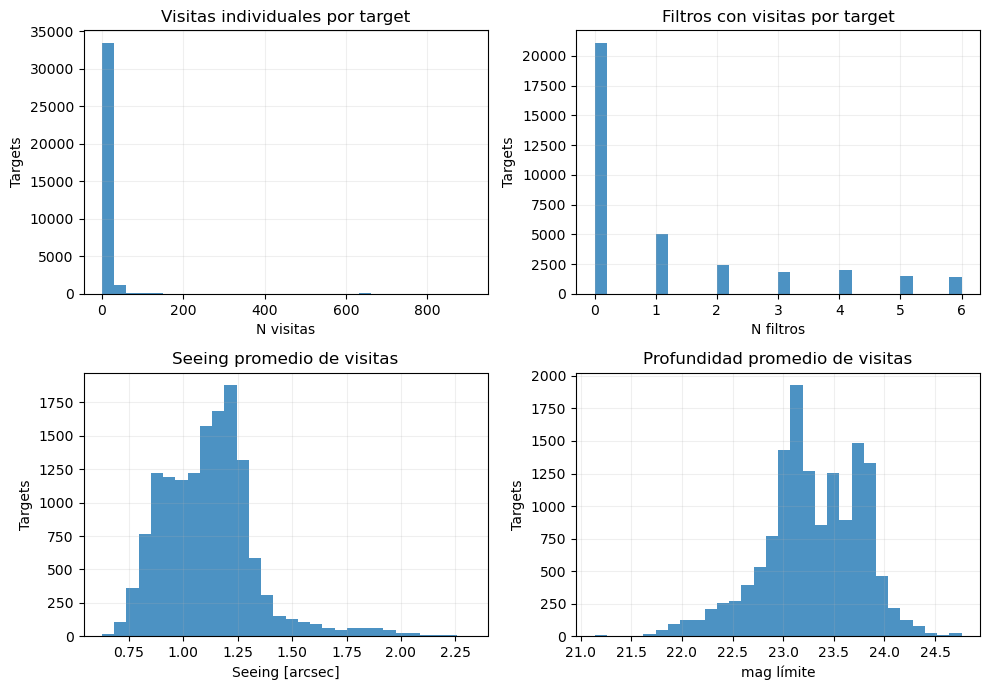

Guardado: /home/karennowo/target_selection/outputs/catalog_enrichment/lastberu_dp2/distributions_dp2.png


In [6]:
visit_seeing = cat[[f"visit_seeing_mean_arcsec_{b}" for b in bands if f"visit_seeing_mean_arcsec_{b}" in cat]].apply(pd.to_numeric, errors="coerce").mean(axis=1)
visit_depth = cat[[f"visit_maglim_mean_{b}" for b in bands if f"visit_maglim_mean_{b}" in cat]].apply(pd.to_numeric, errors="coerce").mean(axis=1)
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
series = [(cat.n_images_total, "Visitas individuales por target", "N visitas"),
          (cat.n_filters, "Filtros con visitas por target", "N filtros"),
          (visit_seeing, "Seeing promedio de visitas", "Seeing [arcsec]"),
          (visit_depth, "Profundidad promedio de visitas", "mag límite")]
for ax, (values, title, xlabel) in zip(axes.flat, series):
    ax.hist(pd.to_numeric(values, errors="coerce").dropna(), bins=30, color="tab:blue", alpha=.8)
    ax.set(title=title, xlabel=xlabel, ylabel="Targets")
    ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(out / "distributions_dp2.png", dpi=200); plt.show(); plt.close(fig)
print(f"Guardado: {out / 'distributions_dp2.png'}")


## Mapas de cobertura en el cielo

Cada punto representa un target y el color indica la cantidad de visitas individuales. Se guarda un mapa total y uno para cada banda.

In [7]:
def save_visit_map(frame, count_col, filename, title):
    values = pd.to_numeric(frame[count_col], errors="coerce").fillna(0)
    fig, ax = plt.subplots(figsize=(10, 5), dpi=180)
    if values.max() > 0:
        sc = ax.scatter(frame["ra_deg"] % 360, frame["dec_deg"], c=values, s=5, cmap="viridis",
                        norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=values.max()), alpha=.8, linewidths=0)
    else:
        sc = ax.scatter(frame["ra_deg"] % 360, frame["dec_deg"], c=values, s=5, cmap="viridis", alpha=.8, linewidths=0)
    ax.set(xlabel="RA [deg]", ylabel="Dec [deg]", title=title)
    ax.invert_xaxis(); ax.grid(alpha=.2); fig.colorbar(sc, ax=ax, label="Visitas individuales")
    fig.tight_layout(); fig.savefig(out / filename, bbox_inches="tight"); plt.close(fig)

save_visit_map(cat, "n_images_total", "sky_map_visits_total.png", "LaStBeRu × DP2 — visitas individuales por target")
for b in bands:
    save_visit_map(cat, f"n_images_{b}", f"sky_map_visits_{b}.png", f"LaStBeRu × DP2 — visitas individuales en banda {b}")
print(f"Mapas guardados en: {out}")


Mapas guardados en: /home/karennowo/target_selection/outputs/catalog_enrichment/lastberu_dp2


## Cutouts

Los cutouts se generan con `generate_reference_catalog_cutouts` usando los coadds existentes y solo para los grades configurados (A y B). Los FITS se guardan si `save_cutout_fits=true` en la configuración.

In [8]:
if RUN_CUTOUTS:
    if "cutout_selected" not in catalog:
        raise RuntimeError("Ejecutá primero la etapa de coadds.")
    catalog = generate_reference_catalog_cutouts(config, catalog, reuse_existing=not REGENERATE_CUTOUTS, fits_output_dir=FITS_OUTPUT_DIR)
    catalog.to_csv(out / "reference_catalog_with_cutouts.csv", index=False)
    print(f"Cutouts y catálogo final guardados en: {out}")
    if "cutout_status" in catalog:
        display(catalog["cutout_status"].value_counts(dropna=False).rename_axis("status").to_frame("targets"))


# Imagen RGB a partir de los FITS generados; se usan z/r/g cuando están disponibles
# y se omiten targets sin al menos tres bandas válidas.
from astropy.io import fits

def make_rgb_images(frame):
    rgb_dir = out / "rgb"
    rgb_dir.mkdir(exist_ok=True)
    for row in frame.loc[frame["cutout_status"].isin(["generated", "reused"])].itertuples(index=False):
        arrays = {}
        for band in bands:
            path = FITS_OUTPUT_DIR / f"{row.target_id}_{band}.fits"
            if path.exists():
                arrays[band] = fits.getdata(path).astype(float)
        rgb = make_science_rgb(arrays)
        plt.imsave(rgb_dir / f"{row.target_id}_rgb.png", rgb)
    return rgb_dir

if RUN_CUTOUTS:
    print(f"RGB guardadas en: {make_rgb_images(catalog)}")


Coadd cutouts:   0%|          | 0/294 [00:00<?, ?target/s]

Coadd cutouts:   4%|▍         | 13/294 [00:00<00:02, 125.63target/s]

Coadd cutouts:  11%|█         | 31/294 [00:00<00:01, 151.75target/s]

Coadd cutouts:  16%|█▌        | 47/294 [00:00<00:01, 136.86target/s]

Coadd cutouts:  21%|██        | 61/294 [00:00<00:01, 129.42target/s]

Coadd cutouts:  26%|██▌       | 75/294 [00:00<00:01, 125.69target/s]

... (17 outputs left out)

Coadd cutouts: 100%|██████████| 294/294 [01:07<00:00,  4.34target/s]

Cutouts y catálogo final guardados en: /home/karennowo/target_selection/outputs/catalog_enrichment/lastberu_dp2


,targets
status,
no_coadd,30471
grade_not_selected,4635
reused,289
generated,5


RGB guardadas en: /home/karennowo/target_selection/outputs/catalog_enrichment/lastberu_dp2/rgb
